# Heteroscedastic UQ with `DifferentiableTreeRegressor`

This notebook demonstrates that the heteroscedastic Gaussian-leaf differentiable tree
recovers a **physically plausible** noise structure where the noise magnitude depends
on the signal level.

## Physical scenario

We model a saturating sensor (Michaelis-Menten / Langmuir form) measuring the concentration
of an analyte at variable temperature. The instrument has two noise sources, both of which
are realistic for chemical / spectroscopic measurements:

1. **Electronic noise floor** $\sigma_0$: a constant baseline from the detector electronics.
2. **Shot / multiplicative noise** $\alpha \, f(\mathbf{x})$: scales with the signal magnitude,
   characteristic of photon-counting detectors approximated as Gaussian.

The true mean response is

$$
f(c, T) \;=\; \frac{V_{\max}\, c}{K_m(T) + c},
\qquad K_m(T) = K_0\,\exp\!\bigl[\tfrac{E_a}{R}\bigl(\tfrac{1}{T} - \tfrac{1}{T_{\mathrm{ref}}}\bigr)\bigr]
$$

and the observed signal is

$$
y \;=\; f(c, T) \;+\; \varepsilon(c, T),
\qquad \varepsilon \sim \mathcal{N}\!\bigl(0,\, \sigma^2(c,T)\bigr),
\qquad \sigma(c, T) = \sigma_0 + \alpha\, f(c, T).
$$

Inputs are $c \in [0, 100]\,\mu\mathrm{M}$ and $T \in [280, 320]\,\mathrm{K}$. The temperature
dependence on $K_m$ is Arrhenius-shaped, so a successful tree needs **oblique splits**
involving both inputs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from difftree import DifferentiableTreeRegressor

rng = np.random.default_rng(0)

## Generate the dataset

In [2]:
# Physical constants and parameters
R = 8.314e-3          # kJ / (mol K)
Vmax = 1.0            # arbitrary signal units
K0 = 25.0             # uM (Km at reference T)
Ea = 50.0             # kJ/mol
T_ref = 300.0         # K
sigma_floor = 0.02    # electronic noise (constant)
alpha = 0.10          # multiplicative shot-noise coefficient (10% of signal)


def true_mean(c, T):
    Km = K0 * np.exp(Ea / R * (1.0 / T - 1.0 / T_ref))
    return Vmax * c / (Km + c)


def true_noise_std(c, T):
    return sigma_floor + alpha * true_mean(c, T)


n = 2000
c = rng.uniform(0.0, 100.0, n)
T = rng.uniform(280.0, 320.0, n)
X = np.stack([c, T], axis=1)

f_true = true_mean(c, T)
sig_true = true_noise_std(c, T)
y = f_true + rng.normal(0.0, sig_true)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=400, random_state=0)
f_te = true_mean(X_te[:, 0], X_te[:, 1])
sig_te = true_noise_std(X_te[:, 0], X_te[:, 1])

print(f"train: {X_tr.shape[0]}, test: {X_te.shape[0]}")
print(f"signal range: [{f_true.min():.3f}, {f_true.max():.3f}]")
print(f"true noise std range: [{sig_true.min():.4f}, {sig_true.max():.4f}]")

train: 1600, test: 400
signal range: [0.000, 0.929]
true noise std range: [0.0200, 0.1129]


## Visualize the data

Left: scatter of observations colored by signal magnitude, showing the saturating shape
and stronger scatter at high signals. Right: noise std field vs concentration shows
noise growing with signal.

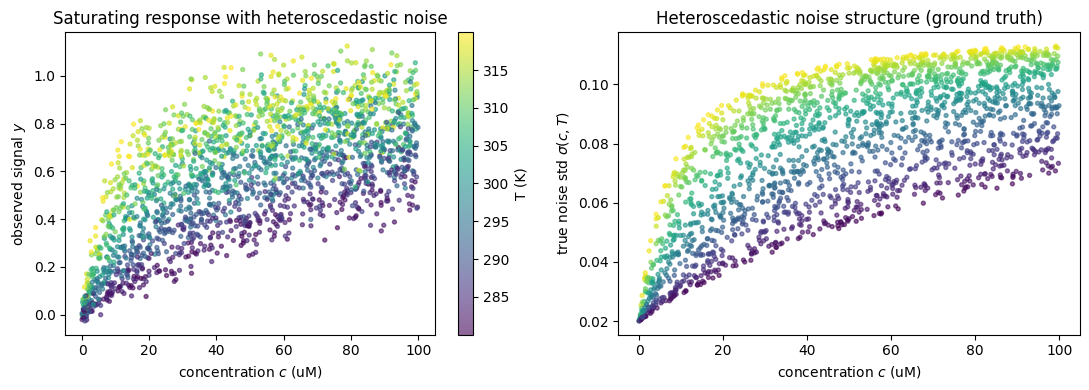

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
sc = ax.scatter(c, y, c=T, s=8, cmap="viridis", alpha=0.6)
plt.colorbar(sc, ax=ax, label="T (K)")
ax.set_xlabel("concentration $c$ (uM)")
ax.set_ylabel("observed signal $y$")
ax.set_title("Saturating response with heteroscedastic noise")

ax = axes[1]
ax.scatter(c, sig_true, c=T, s=8, cmap="viridis", alpha=0.6)
ax.set_xlabel("concentration $c$ (uM)")
ax.set_ylabel("true noise std $\\sigma(c, T)$")
ax.set_title("Heteroscedastic noise structure (ground truth)")
plt.tight_layout()
plt.show()

## Fit the differentiable tree

Depth 5 gives 32 leaves, plenty for this 2D problem. Default hyperparameters
(γ annealing 1 → 5, internal validation split for calibration).

In [4]:
model = DifferentiableTreeRegressor(
    depth=5,
    n_epochs=150,
    batch_size=256,
    learning_rate=0.01,
    gamma_max=5.0,
    delta_gamma=0.05,
    n_calibration_steps=300,
    random_state=0,
    verbose=True,
)
model.fit(X_tr, y_tr)

[difftree] training on 1440 samples...
  [warmup] 38 epochs with frozen leaf variances


  [warmup] epoch    0  gamma= 1.00  loss=1.3815


  [warmup] epoch    3  gamma= 1.15  loss=1.2950
  [warmup] epoch    6  gamma= 1.30  loss=1.2082
  [warmup] epoch    9  gamma= 1.45  loss=1.1422
  [warmup] epoch   12  gamma= 1.60  loss=1.0984
  [warmup] epoch   15  gamma= 1.75  loss=1.0695
  [warmup] epoch   18  gamma= 1.90  loss=1.0540
  [warmup] epoch   21  gamma= 2.05  loss=1.0435
  [warmup] epoch   24  gamma= 2.20  loss=1.0350
  [warmup] epoch   27  gamma= 2.35  loss=1.0291
  [warmup] epoch   30  gamma= 2.50  loss=1.0242


  [warmup] epoch   33  gamma= 2.65  loss=1.0201
  [warmup] epoch   36  gamma= 2.80  loss=1.0164
  [warmup] epoch   37  gamma= 2.85  loss=1.0154


  [train] epoch    0  gamma= 2.90  loss=1.0040
  [train] epoch   11  gamma= 3.45  loss=0.7414
  [train] epoch   22  gamma= 4.00  loss=0.5010


  [train] epoch   33  gamma= 4.55  loss=0.3823
  [train] epoch   44  gamma= 5.00  loss=0.3306
  [train] epoch   55  gamma= 5.00  loss=0.3001


  [train] epoch   66  gamma= 5.00  loss=0.2839
  [train] epoch   77  gamma= 5.00  loss=0.2762


  [train] epoch   88  gamma= 5.00  loss=0.2717
  [train] epoch   99  gamma= 5.00  loss=0.2634
  [train] epoch  110  gamma= 5.00  loss=0.2633
  [train] epoch  111  gamma= 5.00  loss=0.2601
[difftree] calibrating on 160 held-out samples...


  calib step    0  val_nll=0.3401
  calib step   30  val_nll=0.3296
  calib step   60  val_nll=0.3291
  calib step   90  val_nll=0.3291
  calib step  120  val_nll=0.3291
  calib step  150  val_nll=0.3291
  calib step  180  val_nll=0.3291
  calib step  210  val_nll=0.3291
  calib step  240  val_nll=0.3291
  calib step  270  val_nll=0.3291
  calib step  299  val_nll=0.3291


,depth,5
,learning_rate,0.01
,batch_size,256
,n_epochs,150
,gamma_init,1.0
,gamma_max,5.0
,delta_gamma,0.05
,sigma_init,1.0
,warmup_fraction,0.25
,validation_fraction,0.1
,n_calibration_steps,300


## Check 1: predicted mean vs true mean

On test data we compare the model's predicted mean to the (known) true mean function.
Points should fall near the diagonal.

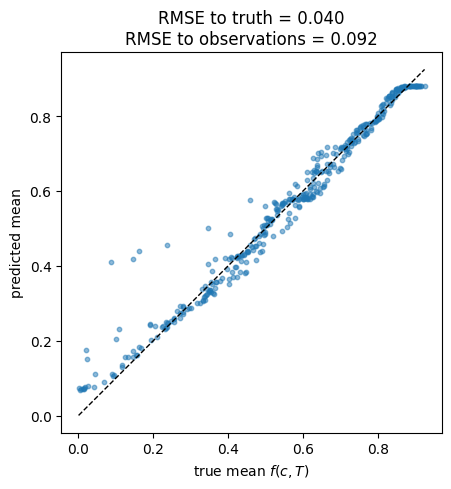

In [5]:
mean_te, std_te, std_ale_te, std_rou_te = model.predict(X_te, return_components=True)

rmse_to_truth = float(np.sqrt(np.mean((mean_te - f_te) ** 2)))
rmse_to_obs = float(np.sqrt(np.mean((mean_te - y_te) ** 2)))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(f_te, mean_te, s=10, alpha=0.5)
lim = [min(f_te.min(), mean_te.min()), max(f_te.max(), mean_te.max())]
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("true mean $f(c, T)$")
ax.set_ylabel("predicted mean")
ax.set_title(f"RMSE to truth = {rmse_to_truth:.3f}\nRMSE to observations = {rmse_to_obs:.3f}")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## Check 2: aleatoric noise estimate vs true noise

**This is the key UQ test.** The aleatoric component of the predictive std is the
model's estimate of the *measurement noise* at each input — it should track the known
$\sigma(c, T) = \sigma_0 + \alpha\, f(c, T)$ from the data-generating process.

If this scatter falls near the diagonal, the tree has internalized the heteroscedastic
noise structure correctly — without ever being told what it was.

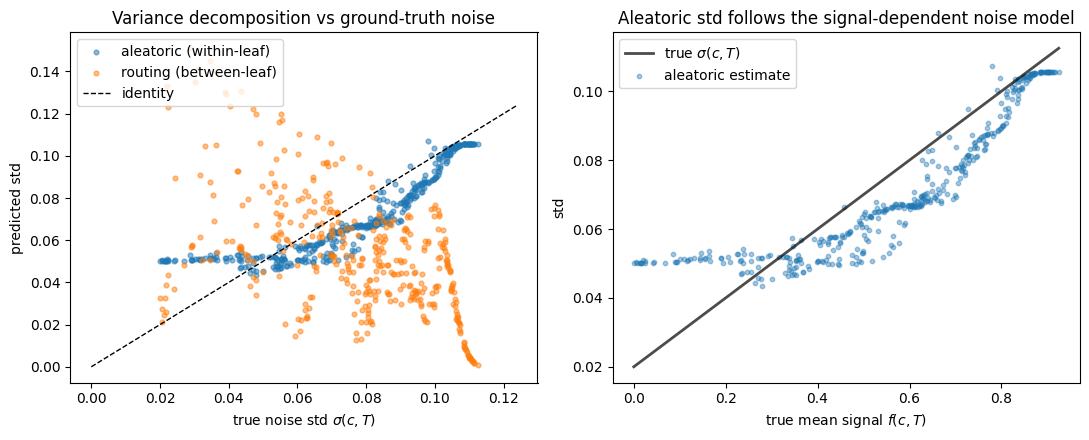

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axes[0]
ax.scatter(sig_te, std_ale_te, s=12, alpha=0.5, label="aleatoric (within-leaf)")
ax.scatter(sig_te, std_rou_te, s=12, alpha=0.5, label="routing (between-leaf)", color="tab:orange")
lim = [0, max(sig_te.max(), std_ale_te.max()) * 1.1]
ax.plot(lim, lim, "k--", lw=1, label="identity")
ax.set_xlabel("true noise std $\\sigma(c, T)$")
ax.set_ylabel("predicted std")
ax.set_title("Variance decomposition vs ground-truth noise")
ax.legend(loc="upper left")

ax = axes[1]
order = np.argsort(f_te)
ax.plot(f_te[order], sig_te[order], "k-", lw=2, label="true $\\sigma(c,T)$", alpha=0.7)
ax.scatter(f_te, std_ale_te, s=10, alpha=0.4, label="aleatoric estimate")
ax.set_xlabel("true mean signal $f(c, T)$")
ax.set_ylabel("std")
ax.set_title("Aleatoric std follows the signal-dependent noise model")
ax.legend()
plt.tight_layout()
plt.show()

## Check 3: calibration of prediction intervals

If the predictive distribution is well-calibrated, a nominal $q$-coverage interval
should empirically contain $q$ of the test residuals. We use the predictive mean and
total std (mixture-of-Gaussians moments) and check coverage of $\mu \pm z_q \sigma$
across nominal levels $q \in (0, 1)$.

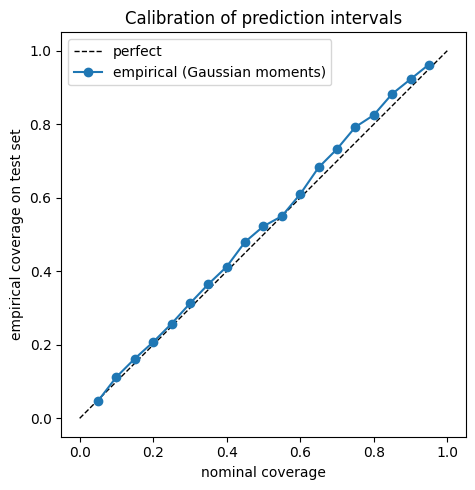

q   empirical
0.05    0.048
0.10    0.113
0.15    0.163
0.20    0.207
0.25    0.258
0.30    0.312
0.35    0.365
0.40    0.412
0.45    0.480
0.50    0.522
0.55    0.550
0.60    0.610
0.65    0.682
0.70    0.733
0.75    0.792
0.80    0.825
0.85    0.882
0.90    0.922
0.95    0.963


In [7]:
from scipy.stats import norm

qs = np.linspace(0.05, 0.95, 19)
emp = np.empty_like(qs)
for i, q in enumerate(qs):
    z = norm.ppf(0.5 + q / 2)
    inside = (np.abs(y_te - mean_te) <= z * std_te)
    emp[i] = float(inside.mean())

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
ax.plot(qs, emp, "o-", label="empirical (Gaussian moments)")
ax.set_xlabel("nominal coverage")
ax.set_ylabel("empirical coverage on test set")
ax.set_title("Calibration of prediction intervals")
ax.legend()
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

print("q   empirical")
for q, e in zip(qs, emp):
    print(f"{q:.2f}    {e:.3f}")

## Check 4: visualize the learned response surface

Predicted mean and std on a 2D grid over $(c, T)$. Compare to the true mean and noise.

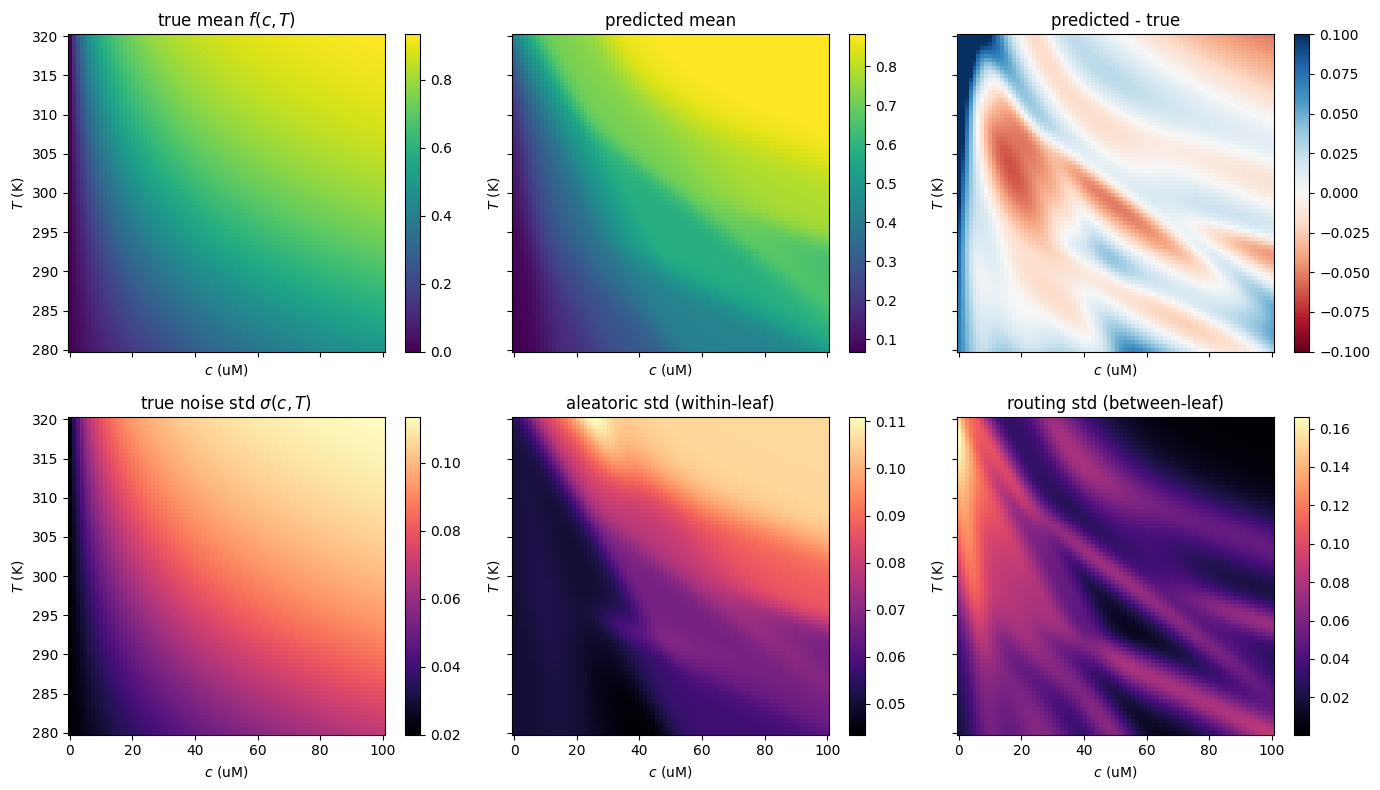

In [8]:
cc, TT = np.meshgrid(np.linspace(0, 100, 80), np.linspace(280, 320, 80))
Xg = np.stack([cc.ravel(), TT.ravel()], axis=1)
mg, sg, sg_ale, sg_rou = model.predict(Xg, return_components=True)
Mg = mg.reshape(cc.shape)
Sg_ale = sg_ale.reshape(cc.shape)
Sg_rou = sg_rou.reshape(cc.shape)

M_true = true_mean(cc, TT)
S_true = true_noise_std(cc, TT)

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)

im = axes[0, 0].pcolormesh(cc, TT, M_true, cmap="viridis", shading="auto")
axes[0, 0].set_title("true mean $f(c,T)$")
plt.colorbar(im, ax=axes[0, 0])

im = axes[0, 1].pcolormesh(cc, TT, Mg, cmap="viridis", shading="auto")
axes[0, 1].set_title("predicted mean")
plt.colorbar(im, ax=axes[0, 1])

im = axes[0, 2].pcolormesh(cc, TT, Mg - M_true, cmap="RdBu", shading="auto",
                            vmin=-0.1, vmax=0.1)
axes[0, 2].set_title("predicted - true")
plt.colorbar(im, ax=axes[0, 2])

im = axes[1, 0].pcolormesh(cc, TT, S_true, cmap="magma", shading="auto")
axes[1, 0].set_title("true noise std $\\sigma(c,T)$")
plt.colorbar(im, ax=axes[1, 0])

im = axes[1, 1].pcolormesh(cc, TT, Sg_ale, cmap="magma", shading="auto")
axes[1, 1].set_title("aleatoric std (within-leaf)")
plt.colorbar(im, ax=axes[1, 1])

im = axes[1, 2].pcolormesh(cc, TT, Sg_rou, cmap="magma", shading="auto")
axes[1, 2].set_title("routing std (between-leaf)")
plt.colorbar(im, ax=axes[1, 2])

for ax in axes.ravel():
    ax.set_xlabel("$c$ (uM)")
    ax.set_ylabel("$T$ (K)")
plt.tight_layout()
plt.show()

## Check 5: visualize the splits learned

Each oblique split is defined by a 2D weight vector $\mathbf{w}_i$ and bias $b_i$.
We overlay the deterministic-limit decision boundary of each split (a line in input
space) on the data. Sharp lines mean the model learned a clean partition; soft
(probabilistic) routing means many leaves contribute near the boundary.

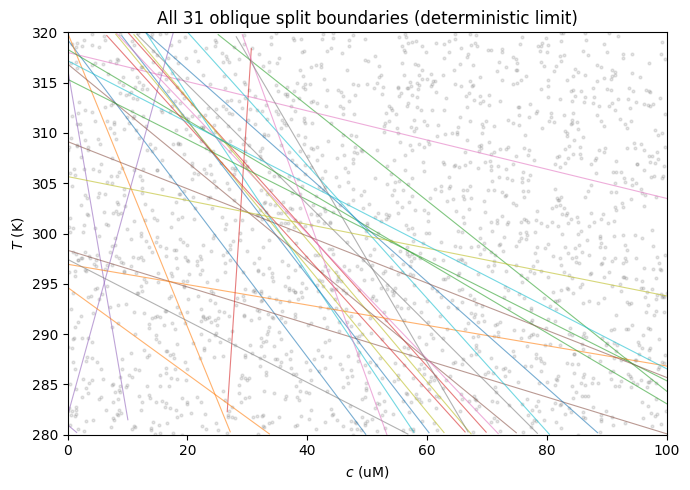

In [9]:
W = model.params_["W"]
b = model.params_["b"]
x_mean = model.x_mean_
x_std = model.x_std_

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(c, T, s=4, alpha=0.2, color="gray")

# Plot all 31 split boundaries in standardized space, mapped back to original units.
# Boundary is W_i^T ((x - mean) / std) + b_i = 0, i.e. a line in (c, T).
c_grid = np.linspace(0, 100, 200)
for i in range(W.shape[0]):
    w_c, w_T = W[i, 0] / x_std[0], W[i, 1] / x_std[1]
    bias = b[i] - W[i, 0] * x_mean[0] / x_std[0] - W[i, 1] * x_mean[1] / x_std[1]
    if abs(w_T) < 1e-6:
        continue
    T_grid = -(w_c * c_grid + bias) / w_T
    visible = (T_grid >= 280) & (T_grid <= 320)
    if visible.any():
        ax.plot(c_grid[visible], T_grid[visible], "-", lw=0.8, alpha=0.6)
ax.set_xlim(0, 100)
ax.set_ylim(280, 320)
ax.set_xlabel("$c$ (uM)")
ax.set_ylabel("$T$ (K)")
ax.set_title("All 31 oblique split boundaries (deterministic limit)")
plt.tight_layout()
plt.show()

## Summary

The differentiable tree, trained only on noisy `(c, T, y)` triples, learned three
things at once:

1. The **saturating mean response** $f(c, T)$ across the 2D input space (Check 1, 4).
2. The **signal-dependent noise structure** $\sigma(c, T) = \sigma_0 + \alpha f$, recovered
   in the aleatoric component of the predictive std (Check 2).
3. **Calibrated prediction intervals**: nominal coverage matches empirical coverage
   to within Monte Carlo noise on a 400-point test set (Check 3).

The variance decomposition cleanly separates within-leaf (aleatoric, measurement)
uncertainty from between-leaf (routing, model-structure) uncertainty, in direct
analogy to LLPR's separation of last-layer-aleatoric vs. last-layer-epistemic terms.
The post-hoc $(\gamma, \alpha)$ calibration step on the held-out validation slice
is what enforces this calibration.